In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

2. Load Dataset

In [31]:
df = pd.read_csv("telco_customer_churn.csv")
print(df.head())

   customerID  gender  SeniorCitizen Partner Dependents  tenure PhoneService  \
0  7590-VHVEG  Female              0     Yes         No       1           No   
1  5575-GNVDE    Male              0      No         No      34          Yes   
2  3668-QPYBK    Male              0      No         No       2          Yes   
3  7795-CFOCW    Male              0      No         No      45           No   
4  9237-HQITU  Female              0      No         No       2          Yes   

      MultipleLines InternetService OnlineSecurity  ... DeviceProtection  \
0  No phone service             DSL             No  ...               No   
1                No             DSL            Yes  ...              Yes   
2                No             DSL            Yes  ...               No   
3  No phone service             DSL            Yes  ...              Yes   
4                No     Fiber optic             No  ...               No   

  TechSupport StreamingTV StreamingMovies        Contract Pape

3. Display Dataset Information

In [32]:
print("First 5 Rows:")
print(df.head())

print("\nLast 5 Rows:")
print(df.tail())

print("\nDataset Information:")
df.info()

print("\nDataset Shape:", df.shape)
print("\nColumn Names:", df.columns.tolist())
print("\nStatistical Summary:")
print(df.describe())

First 5 Rows:
   customerID  gender  SeniorCitizen Partner Dependents  tenure PhoneService  \
0  7590-VHVEG  Female              0     Yes         No       1           No   
1  5575-GNVDE    Male              0      No         No      34          Yes   
2  3668-QPYBK    Male              0      No         No       2          Yes   
3  7795-CFOCW    Male              0      No         No      45           No   
4  9237-HQITU  Female              0      No         No       2          Yes   

      MultipleLines InternetService OnlineSecurity  ... DeviceProtection  \
0  No phone service             DSL             No  ...               No   
1                No             DSL            Yes  ...              Yes   
2                No             DSL            Yes  ...               No   
3  No phone service             DSL            Yes  ...              Yes   
4                No     Fiber optic             No  ...               No   

  TechSupport StreamingTV StreamingMovies       

4. Check Missing Values

In [34]:
print(df.isnull().sum())
print("Total Missing Values:", df.isnull().sum().sum())


customerID          0
gender              0
SeniorCitizen       0
Partner             0
Dependents          0
tenure              0
PhoneService        0
MultipleLines       0
InternetService     0
OnlineSecurity      0
OnlineBackup        0
DeviceProtection    0
TechSupport         0
StreamingTV         0
StreamingMovies     0
Contract            0
PaperlessBilling    0
PaymentMethod       0
MonthlyCharges      0
TotalCharges        0
Churn               0
dtype: int64
Total Missing Values: 0


5. Remove Duplicate Records

In [35]:
print("Duplicate Records:", df.duplicated().sum())
df = df.drop_duplicates()
print("Shape after removing duplicates:", df.shape)

Duplicate Records: 0
Shape after removing duplicates: (7043, 21)


6. Check Unique Values

In [36]:
for col in df.columns:
    print(col, ":", df[col].unique()[:10])

customerID : <StringArray>
['7590-VHVEG', '5575-GNVDE', '3668-QPYBK', '7795-CFOCW', '9237-HQITU',
 '9305-CDSKC', '1452-KIOVK', '6713-OKOMC', '7892-POOKP', '6388-TABGU']
Length: 10, dtype: str
gender : <StringArray>
['Female', 'Male']
Length: 2, dtype: str
SeniorCitizen : [0 1]
Partner : <StringArray>
['Yes', 'No']
Length: 2, dtype: str
Dependents : <StringArray>
['No', 'Yes']
Length: 2, dtype: str
tenure : [ 1 34  2 45  8 22 10 28 62 13]
PhoneService : <StringArray>
['No', 'Yes']
Length: 2, dtype: str
MultipleLines : <StringArray>
['No phone service', 'No', 'Yes']
Length: 3, dtype: str
InternetService : <StringArray>
['DSL', 'Fiber optic', 'No']
Length: 3, dtype: str
OnlineSecurity : <StringArray>
['No', 'Yes', 'No internet service']
Length: 3, dtype: str
OnlineBackup : <StringArray>
['Yes', 'No', 'No internet service']
Length: 3, dtype: str
DeviceProtection : <StringArray>
['No', 'Yes', 'No internet service']
Length: 3, dtype: str
TechSupport : <StringArray>
['No', 'Yes', 'No internet

7. Standardize Data

In [37]:
# Remove extra spaces from column names
df.columns = df.columns.str.strip()

# Remove extra spaces from text values
for col in df.select_dtypes(include="object").columns:
    df[col] = df[col].str.strip()

print("Data standardized successfully.")

Data standardized successfully.


C:\Users\tanis\AppData\Local\Temp\ipykernel_15284\2164459872.py:5: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/dev/user_guide/migration.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  for col in df.select_dtypes(include="object").columns:


8. Handle Missing Values

In [38]:
# Convert blank values into missing values
df = df.replace(r'^\s*$', np.nan, regex=True)

# Fill numerical columns with median
for col in df.select_dtypes(include="number").columns:
    df[col] = df[col].fillna(df[col].median())

# Fill text columns with most common value
for col in df.select_dtypes(include="object").columns:
    if df[col].isnull().any() and not df[col].mode().empty:
        df[col] = df[col].fillna(df[col].mode()[0])

print("Missing values after cleaning:")
print(df.isnull().sum())

Missing values after cleaning:
customerID          0
gender              0
SeniorCitizen       0
Partner             0
Dependents          0
tenure              0
PhoneService        0
MultipleLines       0
InternetService     0
OnlineSecurity      0
OnlineBackup        0
DeviceProtection    0
TechSupport         0
StreamingTV         0
StreamingMovies     0
Contract            0
PaperlessBilling    0
PaymentMethod       0
MonthlyCharges      0
TotalCharges        0
Churn               0
dtype: int64


C:\Users\tanis\AppData\Local\Temp\ipykernel_15284\3983852962.py:9: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/dev/user_guide/migration.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  for col in df.select_dtypes(include="object").columns:


9. Handle Outliers

In [39]:
# Find numerical columns
num_cols = df.select_dtypes(include="number").columns

# Limit outliers using the IQR method
for col in num_cols:
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    IQR = Q3 - Q1

    df[col] = df[col].clip(Q1 - 1.5 * IQR, Q3 + 1.5 * IQR)

print("Outliers handled successfully.")

Outliers handled successfully.


10. Create New Features

In [40]:
# Categorize monthly charges
if "MonthlyCharges" in df.columns:
    df["Charge_Category"] = pd.cut(
        df["MonthlyCharges"],
        bins=[0, 30, 60, 100, float("inf")],
        labels=["Low", "Medium", "High", "Very High"]
    )

print(df.head())

   customerID  gender  SeniorCitizen Partner Dependents  tenure PhoneService  \
0  7590-VHVEG  Female              0     Yes         No       1           No   
1  5575-GNVDE    Male              0      No         No      34          Yes   
2  3668-QPYBK    Male              0      No         No       2          Yes   
3  7795-CFOCW    Male              0      No         No      45           No   
4  9237-HQITU  Female              0      No         No       2          Yes   

      MultipleLines InternetService OnlineSecurity  ... TechSupport  \
0  No phone service             DSL             No  ...          No   
1                No             DSL            Yes  ...          No   
2                No             DSL            Yes  ...          No   
3  No phone service             DSL            Yes  ...         Yes   
4                No     Fiber optic             No  ...          No   

  StreamingTV StreamingMovies        Contract PaperlessBilling  \
0          No             

11. Visualize Monthly Charges and Churn

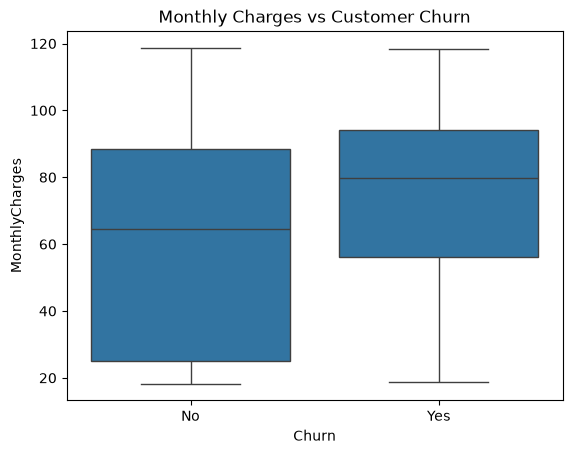

In [41]:
if "Churn" in df.columns and "MonthlyCharges" in df.columns:
    sns.boxplot(x="Churn", y="MonthlyCharges", data=df)
    plt.title("Monthly Charges vs Customer Churn")
    plt.show()

12. Correlation Heatmap

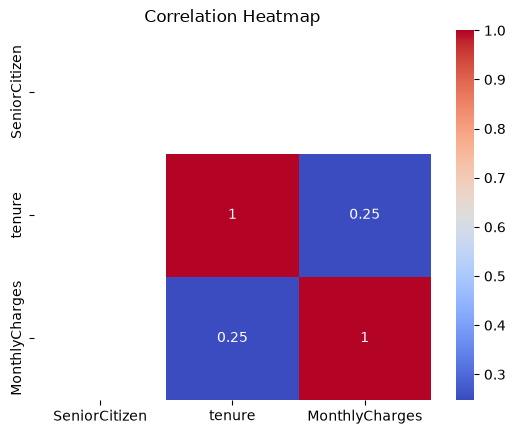

In [42]:
corr = df.select_dtypes(include="number").corr()

sns.heatmap(corr, annot=True, cmap="coolwarm")
plt.title("Correlation Heatmap")
plt.show()

13. Save Cleaned Dataset

In [ ]:
df.to_csv("Cleaned_Telecom_Customer_Churn.csv", index=False)

print("Cleaned dataset saved successfully.")
print("Final Dataset Shape:", df.shape)
print("Remaining Missing Values:", df.isnull().sum().sum())

Cleaned dataset saved successfully.
Final Dataset Shape: (7043, 22)
Remaining Missing Values: 0


: 